# What the speech engines get wrong, and how much it matters

Four data sets, three engines on all of them (two more on EdAcc), and about 37,000 places
where four Python searches found an engine's transcript differing from the reference
(the "true" transcript) in a way that might matter: a "not" lost or added, a number
changed, words invented in silence, speech skipped, the speaker's grammar rewritten.

A rule can find those places but can't say whether the meaning really changed. So Claude
Sonnet 5.5 read every one of them, with a minute of both transcripts around it, and
answered: is the meaning the same, reworded, changed, the opposite, or garbled; how bad
is it (severity 0 to 4); and might the reference itself be wrong here? A second judge,
Qwen 3.8 27B, runs on the laptop's own card and has read part of them so far (section 5
says which).

This notebook asks five questions of those answers:

1. How often is each rule right?
2. How many serious errors does each engine make per hour, beside its error rate?
3. Does a low error rate mean few serious errors?
4. How often is the "true" transcript itself in doubt?
5. How often do the two judges agree?

**Words used below.**

- **Serious**: Sonnet says the meaning changed or was reversed, at severity 3 or 4
  ("a reader would get a fact or the point wrong").
- **Reversal**: Sonnet says the engine's text means the opposite of what was said.
- **Rule finds**: the places the four searches found. The other 6,848 places are where
  *every* engine disagrees with the reference; those are more often the reference's
  mistake than the engines', so they are left out of questions 1-3 (and kept for 4).
  Places where Sonnet says the reference is wrong, or the speaker misspoke, are left
  out of 1-3 too.

**Read this before the numbers.** Nothing here has been checked by ear yet; these are a
language model's readings of text. The judge bench (300 cases to label by listening) is
how they will be checked. And the searches look for particular kinds of error, so the
counts per hour are what the searches found, not every error an engine makes.

Everything is read from `findings/`: the cases (`judge/full-v1.csv`), the two judges'
answers, and one row per recording and engine (`recordings.csv`).

In [1]:
import io
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FINDINGS = Path("..") / "findings"


def answers(file):
    """One judge's answers to the meaning question, one row per case.
    The Qwen judge may still be adding to its file, so a half-written last row is left out."""
    text = (FINDINGS / "judge" / file).read_text(encoding="utf-8")
    if not text.endswith("\n"):
        text = text[:text.rfind("\n") + 1]
    a = pd.read_csv(io.StringIO(text), dtype=str, keep_default_na=False)
    a = a[(a.ask == "meaning") & (a.valid == "True")].drop_duplicates("case", keep="last")
    return pd.DataFrame([{"case": c, **json.loads(x)} for c, x in zip(a.case, a.answer)])


cases = pd.read_csv(FINDINGS / "judge" / "full-v1.csv", dtype=str, keep_default_na=False)
sonnet = answers("answers-claude-sonnet-5-5-full-v1.csv").add_prefix("s_").rename(columns={"s_case": "case"})
qwen = answers("answers-qwen3.8-27b-full-v1.csv").add_prefix("q_").rename(columns={"q_case": "case"})
recordings = pd.read_csv(FINDINGS / "recordings.csv", dtype={"recording": str})

t = cases.merge(sonnet, on="case")
t["s_severity"] = t.s_severity.astype(int)
t["matters"] = t.s_meaning.isin(["changed", "opposite"])
t["serious"] = t.matters & (t.s_severity >= 3)
t["reversal"] = t.s_meaning == "opposite"
t["rule_find"] = (t.source == "candidates") & (t.s_reference_doubt != "yes") & (t.s_misspoke != "yes") & (t.not_counted == "")
found = t[t.rule_find]

print(f"{len(t):,} places, all read by Sonnet; {len(found):,} rule finds kept for questions 1-3")
print(f"Sonnet calls {t.serious.sum():,} serious and {t.reversal.sum():,} reversals")
print(f"Qwen has read {len(qwen):,} of them so far")

37,261 places, all read by Sonnet; 29,528 rule finds kept for questions 1-3
Sonnet calls 2,597 serious and 1,895 reversals
Qwen has read 23,468 of them so far


## 1. How often is each rule right?

For each rule, the share of its finds Sonnet calls a real change of meaning, a serious
one, and a reversal.

In [2]:
NAMES = {("meaning", "negation"): "a \"not\" lost or added", ("meaning", "number"): "a number changed",
         ("meaning", "word"): "another word swapped", ("meaning", "added"): "a word added",
         ("meaning", "dropped"): "a word dropped", ("skips", "long"): "a long stretch skipped",
         ("skips", "short"): "a short stretch skipped", ("skips", "whole-turn"): "a whole turn skipped",
         ("invented", "phrase"): "a phrase invented", ("invented", "word"): "a word invented",
         ("edits", "aint"): "\"ain't\" written another way", ("edits", "habitual-be"): "habitual \"be\" rewritten",
         ("edits", "zero-copula"): "a left-out \"is\" or \"are\" put back", ("edits", "third-person-s"): "an \"-s\" added to a verb",
         ("edits", "negative-concord"): "a double negative rewritten", ("edits", "was-levelling"): "\"we was\" made \"we were\"",
         ("edits", "completive-done"): "\"done\" (as in \"I done told you\") rewritten",
         ("edits", "existential-it"): "\"it's\" (for \"there's\") rewritten", ("edits", "finna"): "\"finna\" rewritten"}
rules = found.groupby(["kind", "subkind"]).agg(finds=("case", "size"), changed=("matters", "mean"),
                                              serious=("serious", "mean"), reversal=("reversal", "mean"))
rules[["changed", "serious", "reversal"]] = (100 * rules[["changed", "serious", "reversal"]]).round(1)
rules["serious finds"] = (rules.finds * rules.serious / 100).round().astype(int)
rules.index = [f"{kind}: {NAMES.get((kind, sub), sub)}" for kind, sub in rules.index]
rules.sort_values("serious", ascending=False).rename(columns={
    "changed": "% meaning changed", "serious": "% serious", "reversal": "% reversed"})

,finds,% meaning changed,% serious,% reversed,serious finds
"meaning: a ""not"" lost or added",2138,81.0,55.3,58.6,1182
meaning: a number changed,644,75.5,54.3,0.0,350
skips: a long stretch skipped,50,80.0,46.0,2.0,23
"edits: ""ain't"" written another way",594,41.2,20.4,21.4,121
skips: a short stretch skipped,459,79.7,17.0,0.2,78
skips: a whole turn skipped,252,97.2,9.1,0.0,23
"edits: ""done"" (as in ""I done told you"") rewritten",45,11.1,6.7,6.7,3
edits: a double negative rewritten,296,25.0,5.7,3.7,17
invented: a phrase invented,206,68.0,1.9,0.0,4
meaning: another word swapped,19689,44.1,1.8,0.8,354


**Two rules carry most of what matters.** About half of what the "not" rule and the number
rule find is serious by Sonnet's reading. The broad word-swap rule finds far more places
(about 20,000) but under 2% of them are serious, so it is mostly noise; it still turns up
about as many serious cases as the number rule does, because it looks at so much more.

The edits rules, which look for African American English grammar being rewritten into
standard English, are mostly not serious by this measure, except for "ain't": rewriting
"ain't" as "is" or "am" sometimes reverses the sentence. That is a finding in itself: an
edit that tidies the grammar can be harmless, but this one flips the meaning.

A skipped stretch is almost always a real change (the words are gone), but usually a
small one: Sonnet rarely calls it serious unless it is long.

## 2. Serious errors per hour, beside the error rate

The error rate is the usual score: words swapped, dropped or added, over the reference's
words (punctuation, capitals and fillers ignored). Beside it, how many serious errors and
reversals the searches and Sonnet found per hour of audio.

In [3]:
hours = recordings.groupby(["corpus", "engine"]).minutes.sum() / 60
words = recordings.groupby(["corpus", "engine"])[["substituted", "dropped", "added", "reference_words"]].sum()
counts = found.groupby(["corpus", "engine"])[["serious", "reversal"]].sum()
engines = pd.DataFrame({
    "hours": hours.round(0).astype(int),
    "error rate %": (100 * (words.substituted + words.dropped + words.added) / words.reference_words).round(1),
    "serious": counts.serious.astype(int),
    "serious per hour": (counts.serious / hours).round(2),
    "reversals per hour": (counts.reversal / hours).round(2),
})
engines

hours  error rate %  serious  serious per hour  \
corpus     engine                                                     
coraal     Parakeet    161          13.5      381              2.37   
           Qwen3       161          13.6      315              1.96   
           Whisper     161          17.1      349              2.17   
earnings22 Parakeet    120          11.8      186              1.55   
           Qwen3       120          11.3       92              0.77   
           Whisper     120          12.4      105              0.88   
edacc      Canary       36          15.7       59              1.66   
           Granite      36          17.8       74              2.08   
           Parakeet     36          12.8       64              1.80   
           Qwen3        36          11.2       36              1.01   
           Whisper      36          13.9       60              1.69   
scotus     Parakeet    310           5.6      219              0.71   
           Qwen3       310           4.6      117              0.38   
           Whisper     310           5.9      109              0.35   

                     reversals per hour  
corpus     engine                        
coraal     Parakeet                2.09  
           Qwen3                   1.88  
           Whisper                 1.81  
earnings22 Parakeet                0.37  
           Qwen3                   0.28  
           Whisper                 0.19  
edacc      Canary                  1.66  
           Granite                 1.77  
           Parakeet                1.52  
           Qwen3                   0.95  
           Whisper                 1.63  
scotus     Parakeet                0.38  
           Qwen3                   0.27  
           Whisper                 0.24

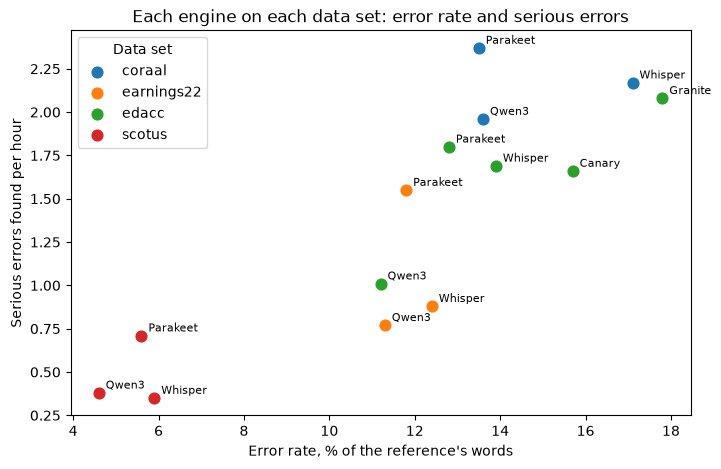

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for corpus, g in engines.groupby(level=0):
    ax.scatter(g["error rate %"], g["serious per hour"], s=60, label=corpus)
    for (_, engine), row in g.iterrows():
        ax.annotate(engine, (row["error rate %"], row["serious per hour"]), xytext=(5, 3),
                    textcoords="offset points", fontsize=8)
ax.set_xlabel("Error rate, % of the reference's words")
ax.set_ylabel("Serious errors found per hour")
ax.set_title("Each engine on each data set: error rate and serious errors")
ax.legend(title="Data set")
plt.show()

**The ranking changes, and Parakeet is the engine it changes for.** On the Supreme Court
arguments Parakeet's error rate sits between Qwen3's and Whisper's, but it makes about
twice as many serious errors per hour as either. On the earnings calls it makes about
twice as many as Qwen3 for nearly the same error rate. On CORAAL its error rate is about
the same as Qwen3's (13.5% against 13.6%) and it makes the most serious errors of the
three. Whisper has the highest error rate on CORAAL but not the most serious errors.
Only on EdAcc do the two orders roughly agree (Qwen3 best on both).

Across data sets the two do go together: the Supreme Court arguments, clean audio with
practised speakers, have both the lowest error rates and a fraction of the serious errors
per hour of the conversations, interviews and calls. The data sets differ more than the
engines do. It is within a data set, choosing between engines, that the error rate
misleads.

Which kinds of error make the difference between the three main engines, over all four
data sets:

In [5]:
three = found[found.engine.isin(["Parakeet", "Qwen3", "Whisper"])]
group = three.subkind.where(three.subkind.isin(["negation", "number", "aint"]), three.kind)
by_kind = three[three.serious].groupby([group[three.serious], "engine"]).size().unstack(fill_value=0)
hours_three = hours.groupby(level=1).sum()[["Parakeet", "Qwen3", "Whisper"]]
(by_kind / hours_three).round(2).rename(index={"negation": "a \"not\" lost or added", "number": "a number changed",
                                               "aint": "\"ain't\" rewritten", "meaning": "other word changes"})

engine,Parakeet,Qwen3,Whisper
subkind,,,
"""ain't"" rewritten",0.07,0.07,0.05
edits,0.01,0.01,0.02
invented,0.00,0.00,0.00
other word changes,0.19,0.16,0.20
"a ""not"" lost or added",0.67,0.52,0.53
a number changed,0.30,0.12,0.13
skips,0.12,0.01,0.06


Parakeet's extra serious errors are mostly numbers (more than twice the others' rate)
and skipped speech, with more lost or added "not"s as well. Numbers matter most in the
earnings calls, which is why Parakeet does worst there.

## 3. Does a low error rate mean few serious errors?

Recording by recording (each engine on each recording over 10 minutes long): the error
rate against serious errors per hour. The number is Spearman's rank correlation: 1 would
mean the recordings with higher error rates always have more serious errors, 0 no link.

In [6]:
per_recording = found.groupby(["corpus", "recording", "engine"])[["serious"]].sum().reset_index()
r = recordings.merge(per_recording, on=["corpus", "recording", "engine"], how="left").fillna({"serious": 0})
r = r[r.minutes >= 10].copy()
r["serious per hour"] = r.serious / (r.minutes / 60)
link = r.groupby("corpus").apply(lambda g: pd.Series({
    "recordings x engines": len(g),
    "rank correlation": round(g.error_rate.corr(g["serious per hour"], method="spearman"), 2)}))
better_half = r[r.error_rate <= r.groupby("corpus").error_rate.transform("median")]
print(f"All together: {r.error_rate.corr(r['serious per hour'], method='spearman'):.2f}. "
      f"{100 * better_half.serious.sum() / r.serious.sum():.0f}% of the serious errors are in the half of "
      "recordings with the lower error rates (by data set).")
link

All together: 0.38. 39% of the serious errors are in the half of recordings with the lower error rates (by data set).


,recordings x engines,rank correlation
corpus,,
coraal,726.0,0.31
earnings22,375.0,0.30
edacc,375.0,0.32
scotus,774.0,0.11


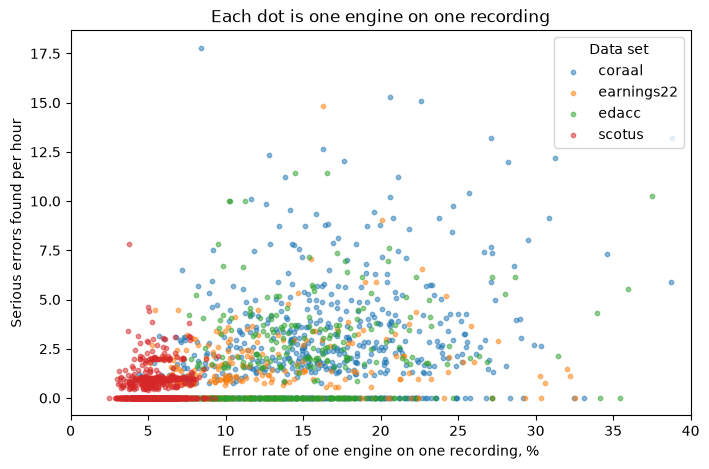

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for corpus, g in r.groupby("corpus"):
    ax.scatter(g.error_rate, g["serious per hour"], s=10, alpha=0.5, label=corpus)
ax.set_xlim(0, 40)
ax.set_xlabel("Error rate of one engine on one recording, %")
ax.set_ylabel("Serious errors found per hour")
ax.set_title("Each dot is one engine on one recording")
ax.legend(title="Data set")
plt.show()

**Only a weak link.** Recordings with higher error rates do tend to have more serious
errors, but the correlation is around 0.3 in three data sets and close to nothing in the
Supreme Court arguments. Well over a third of the serious errors are in the recordings
with the *better* half of the error rates. An error rate says how much of a transcript is
wrong, not whether the wrong part matters, so a good score is no guarantee that the
transcript says what the speaker said.

## 4. How often is the "true" transcript in doubt?

Sonnet was also asked whether the reference itself looks wrong at each place, and whether
the speaker seemed to misspeak. Split into the rule finds and the places where every
engine disagrees with the reference.

In [8]:
WHO = {"scotus": "Supreme Court (official court reporter)", "coraal": "CORAAL (trained transcribers, checked twice)",
       "edacc": "EdAcc (professional transcribers)", "earnings22": "Earnings-22 (Rev's transcribers)"}
doubt = t.groupby(["corpus", "source"]).agg(
    places=("case", "size"),
    reference_wrong=("s_reference_doubt", lambda s: (s == "yes").mean() * 100),
    maybe=("s_reference_doubt", lambda s: (s == "maybe").mean() * 100),
    misspoke=("s_misspoke", lambda s: (s != "no").mean() * 100)).round(1)
doubt = doubt.rename(index=WHO, level=0).rename(index={"candidates": "rule finds", "all-agree": "every engine differs"}, level=1)
doubt.rename(columns={"reference_wrong": "% reference wrong", "maybe": "% maybe wrong", "misspoke": "% speaker misspoke (yes or maybe)"})

places  \
corpus                                       source                         
CORAAL (trained transcribers, checked twice) every engine differs    1927   
                                             rule finds             15432   
Earnings-22 (Rev's transcribers)             every engine differs    3527   
                                             rule finds              6265   
EdAcc (professional transcribers)            every engine differs     388   
                                             rule finds              3613   
Supreme Court (official court reporter)      every engine differs    1006   
                                             rule finds              5103   

                                                                   % reference wrong  \
corpus                                       source                                    
CORAAL (trained transcribers, checked twice) every engine differs                7.0   
                                             rule finds                          0.3   
Earnings-22 (Rev's transcribers)             every engine differs               55.2   
                                             rule finds                         11.5   
EdAcc (professional transcribers)            every engine differs               18.0   
                                             rule finds                          1.2   
Supreme Court (official court reporter)      every engine differs               10.6   
                                             rule finds                          1.0   

                                                                   % maybe wrong  \
corpus                                       source                                
CORAAL (trained transcribers, checked twice) every engine differs           20.7   
                                             rule finds                      5.0   
Earnings-22 (Rev's transcribers)             every engine differs           30.5   
                                             rule finds                     13.9   
EdAcc (professional transcribers)            every engine differs           43.0   
                                             rule finds                      6.5   
Supreme Court (official court reporter)      every engine differs           19.5   
                                             rule finds                      2.8   

                                                                   % speaker misspoke (yes or maybe)  
corpus                                       source                                                   
CORAAL (trained transcribers, checked twice) every engine differs                                3.0  
                                             rule finds                                          0.5  
Earnings-22 (Rev's transcribers)             every engine differs                                5.6  
                                             rule finds                                          2.7  
EdAcc (professional transcribers)            every engine differs                                7.7  
                                             rule finds                                          1.4  
Supreme Court (official court reporter)      every engine differs                               18.3  
                                             rule finds                                          2.2

**The earnings-call transcripts are the least trusted by far.** Where every engine
disagrees with them, Sonnet thinks the reference is wrong more than half the time, and
it doubts the reference at about one in nine rule finds as well. CORAAL's transcripts,
made and checked twice for linguists, are doubted least.

The Supreme Court is different: where every engine disagrees with the court reporter,
Sonnet thinks the *speaker* misspoke at about one place in five, far more than in any
other data set and more often than it says the reporter was wrong. There the reporter
has usually tidied a slip, which is what a court reporter is expected to do. So "the engines
all disagree with the record" means different things in different data sets: a slip in
the reference on the earnings calls, an edit by the reporter at the Court.

## 5. How often do the two judges agree?

Both judges were asked the same question about the same minute of text, though on Whisper's
cases their text can differ a little, because its split words were joined back between the two
runs: the meaning label, the severity, a follow-up for the kind of case, whether the
reference looks wrong, and whether the speaker misspoke. The one difference is that Qwen
reasons for about 1,100 tokens before it answers, and Sonnet hardly at all. Qwen is a
second opinion: it shows which labels are a judgement call. It is also not a Claude model,
which matters because the answer key used to pick Sonnet was written by Claude reviewers.

**The cases Qwen has read are not a random sample.** It read the negation cases first, then
numbers, then some of everything else. Since 30 October it reads only a target list
(`judge/qwen-targets-v1.csv`): every case Sonnet called "changed" or "opposite", and a random
10% of the rest, so it can still find changes Sonnet missed. So the figures below are given
per group, or for each thing Sonnet said, rather than as one number for everything.

Two adjustments before comparing, both from a review of the answers:

- Both judges sometimes contradict themselves ("changed" with severity 0, or "changed"
  with a follow-up answer saying the meaning is kept). A case is left out if either judge
  does, so both are held to the same rule.
- Both judges sometimes say "changed" while their own follow-up answer says a "not" was
  lost or added. Those are counted as "opposite" for both.

The rule does not catch every odd answer, and those are kept. Reading some by hand, Qwen
sometimes calls an inserted "really" or "just" the same meaning, where "reworded" fits the
prompt better. It sometimes says the reference looks wrong but still grades the engine as
changing the meaning. And it sometimes doubts the reference even when another engine wrote
exactly the reference's words.

In [9]:
both = t.merge(qwen, on="case")
both["q_severity"] = both.q_severity.astype(int)
same_meaning = {"same thing", "same meaning, other words", "meaning kept", "no change"}


def contradicts(meaning, severity, follow_up):
    """An answer that disagrees with itself: a change at severity 0, or a label and follow-up that clash."""
    return ((meaning.isin(["changed", "opposite"]) & ((severity == 0) | follow_up.isin(same_meaning)))
            | (meaning.isin(["same", "reworded"]) & follow_up.isin(["changes meaning", "garble", "negation lost", "negation added"])))


s_contra = contradicts(both.s_meaning, both.s_severity, both.s_follow_up)
q_contra = contradicts(both.q_meaning, both.q_severity, both.q_follow_up)
negation = ["negation lost", "negation added"]
fix = lambda meaning, follow_up: meaning.where(~((meaning == "changed") & follow_up.isin(negation)), "opposite")
kept = both[~(s_contra | q_contra)].assign(sonnet=lambda d: fix(d.s_meaning, d.s_follow_up), qwen=lambda d: fix(d.q_meaning, d.q_follow_up))
matters = lambda m: m.isin(["changed", "opposite"])

# Groups: the "not" and number rules, the other rules by kind, and the places where every engine differs.
group = kept.subkind.replace({"aint": "negation"})
group = group.where(group.isin(["negation", "number"]), kept.kind.replace({"meaning": "other word changes"}))
group = group.where(kept.source == "candidates", "every engine differs")
agreement = kept.groupby(group).apply(lambda g: pd.Series({
    "cases": len(g), "% same label": round(100 * (g.sonnet == g.qwen).mean()),
    "% same 'meaning changed or not'": round(100 * (matters(g.sonnet) == matters(g.qwen)).mean()),
    "Sonnet: opposite": (g.sonnet == "opposite").sum(), "Qwen: opposite": (g.qwen == "opposite").sum(),
    "both: opposite": ((g.sonnet == "opposite") & (g.qwen == "opposite")).sum()}), include_groups=False)
print(f"Both judges have read {len(both):,} cases. Sonnet contradicts itself on {s_contra.sum():,} "
      f"({100 * s_contra.mean():.1f}%), Qwen on {q_contra.sum():,} ({100 * q_contra.mean():.1f}%). "
      f"On the {len(kept):,} left: same label "
      f"{100 * (kept.sonnet == kept.qwen).mean():.0f}%.")
agreement.rename_axis("group").sort_values("cases", ascending=False)

Both judges have read 23,468 cases. Sonnet contradicts itself on 654 (2.8%), Qwen on 814 (3.5%). On the 22,144 left: same label 80%.


,cases,% same label,% same 'meaning changed or not',Sonnet: opposite,Qwen: opposite,both: opposite
group,,,,,,
other word changes,12341,78,81,170,184,137
every engine differs,4042,82,85,339,350,326
negation,2576,83,89,1787,1768,1646
edits,1408,80,89,22,10,8
skips,670,94,95,2,0,0
number,662,87,91,0,0,0
invented,445,76,80,1,1,1


For each label Sonnet gave, what Qwen said (each row adds up to 100%):

In [10]:
by_label = pd.crosstab(kept.sonnet.rename("Sonnet says"), kept.qwen.rename("Qwen says (%)"), normalize="index").mul(100).round()
by_label["cases"] = kept.sonnet.value_counts()
by_label

Qwen says (%),changed,garbled,opposite,reworded,same,cases
Sonnet says,,,,,,
changed,88.0,1.0,0.0,7.0,3.0,13684
garbled,58.0,34.0,5.0,1.0,2.0,2276
opposite,3.0,3.0,91.0,1.0,1.0,2321
reworded,18.0,0.0,1.0,56.0,25.0,1572
same,6.0,1.0,1.0,10.0,82.0,2291


**Do they pick out the same serious errors?** Serious means "changed" or "opposite" at
severity 3 or 4, as in sections 1-3. And where both say the meaning changed, how close are
their severities?

In [11]:
kept = kept.assign(s_serious=matters(kept.sonnet) & (kept.s_severity >= 3),
                   q_serious=matters(kept.qwen) & (kept.q_severity >= 3))
print(f"Serious: Sonnet {kept.s_serious.sum():,}, Qwen {kept.q_serious.sum():,}, both {(kept.s_serious & kept.q_serious).sum():,} "
      f"(Qwen agrees with {100 * (kept.s_serious & kept.q_serious).sum() / kept.s_serious.sum():.0f}% of Sonnet's)")
changed_both = kept[matters(kept.sonnet) & matters(kept.qwen)]
gap = changed_both.q_severity - changed_both.s_severity
print(f"Where both say the meaning changed ({len(changed_both):,} cases): Qwen's severity is {gap.mean():+.2f} "
      f"on average; the same on {100 * (gap == 0).mean():.0f}%, within one step on {100 * (gap.abs() <= 1).mean():.0f}%")

Serious: Sonnet 2,574, Qwen 3,003, both 2,151 (Qwen agrees with 84% of Sonnet's)
Where both say the meaning changed (14,351 cases): Qwen's severity is +0.39 on average; the same on 55%, within one step on 98%


**Does Qwen find changes Sonnet missed?** The random 10% of the cases Sonnet called same,
reworded or garbled answers this without the skew of the rest.

In [12]:
targets = pd.read_csv(FINDINGS / "judge" / "qwen-targets-v1.csv", dtype=str)
rest = kept[kept.case.isin(targets[targets.why.str.startswith("random")].case)]
print(f"{len(rest):,} of the random 10% read so far. Qwen calls {matters(rest.qwen).sum()} of them changed or opposite, "
      f"{rest.q_serious.sum()} serious.")
pd.crosstab(rest.sonnet.rename("Sonnet says"), rest.qwen.rename("Qwen says"), margins=True)

1,956 of the random 10% read so far. Qwen calls 639 of them changed or opposite, 42 serious.


Qwen says,changed,garbled,opposite,reworded,same,All
Sonnet says,,,,,,
garbled,487,246,7,7,12,759
reworded,93,2,1,282,123,501
same,49,1,2,52,592,696
All,629,249,10,341,727,1956


**Is the reference wrong, and did the speaker misspeak?** The reference question on the
places where every engine differs from the reference; the misspoke question on all.

In [13]:
differs = both[both.source == "all-agree"]
print(f"Every engine differs: {len(differs):,} cases; same answer on 'reference wrong?' "
      f"{100 * (differs.s_reference_doubt == differs.q_reference_doubt).mean():.0f}%")
display(pd.crosstab(differs.s_reference_doubt.rename("Sonnet: reference wrong?"),
                    differs.q_reference_doubt.rename("Qwen"), margins=True))
pd.crosstab(both.s_misspoke.rename("Sonnet: speaker misspoke?"), both.q_misspoke.rename("Qwen"), margins=True)

Every engine differs: 4,633 cases; same answer on 'reference wrong?' 71%


Qwen,maybe,no,yes,All
Sonnet: reference wrong?,,,,
maybe,627,163,505,1295
no,417,1060,84,1561
yes,166,23,1588,1777
All,1210,1246,2177,4633


Qwen,maybe,no,yes,All
Sonnet: speaker misspoke?,,,,
maybe,108,379,14,501
no,1016,21841,89,22946
yes,0,20,1,21
All,1124,22240,104,23468


**The two judges agree on most cases, and on most of the serious ones.** They give the same
label nearly four times in five, and agree best on numbers and skipped speech. Qwen
confirms most of Sonnet's serious errors.

Where they differ, it is mostly over labels rather than danger:

- **"Garbled" against "changed".** Where Sonnet calls a passage nonsense, Qwen usually
  calls it "changed": it reads a meaning into it where Sonnet gives up. These are mostly
  severity 2.
- **On reversals they agree about nine times in ten, after the adjustment.** On the raw
  labels Qwen looks more cautious: it agrees with only about three in four of Sonnet's
  "opposite". But that is mostly Qwen answering "changed" while its own follow-up says a
  "not" was lost, which is a reversal in all but the label.
- **"Reworded" is a fuzzy line for both.** Where Sonnet says reworded, Qwen splits
  between same, reworded and changed.
- **Qwen rates severity about a third of a step higher**, but nearly always within one
  step of Sonnet.

On the random 10% of what Sonnet thought harmless, Qwen rates only a few cases serious, so
Sonnet does not seem to miss many serious errors. Both judges often say the reference
itself is wrong where every engine differs from it, and agree on most of those. Neither
can tell when a speaker misspoke: they almost never say yes, and hardly ever on the same
case, which needs the audio.

The cases they truly split on, one saying the meaning is kept and the other that it
changed, are the ones most worth hearing on the judge bench.

## What this adds up to, and what is next

- The searches that matter are the "not" and number rules; the broad word-swap rule is
  mostly noise.
- The error rate ranks the engines differently from the serious errors, and on a single
  recording it says little about whether the serious errors are there. That is the case
  for judging transcripts by what the errors do, not only by how many there are.
- Parakeet makes the most serious errors per hour on three of the four data sets, mostly
  numbers and skipped speech, despite a competitive error rate.
- How far the "true" transcript can be trusted differs by data set, so "every engine
  disagrees with the record" has to be read differently in each.
- A second judge, a different model, agrees with Sonnet on most of the serious errors;
  where they differ it is mostly over what to call a garbled or reworded passage.

All of this rests on one language model's reading of text. Next: label the 300 judge-bench
cases by ear, and check how often Sonnet's "serious" matches what a listener hears.